In [13]:
import sys
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [14]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.5,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=80,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [15]:
def radial_stretch_from_point(img, stretch_factor, center):
    h, w = img.shape[:2]
    cx, cy = center

    # pixel grid
    y, x = np.indices((h, w), dtype=np.float32)

    # shift relative to chosen center
    dx = x - cx
    dy = y - cy

    # scale vectors
    scale = 1 / stretch_factor

    map_x = (cx + dx * scale).astype(np.float32)
    map_y = (cy + dy * scale).astype(np.float32)
    
    stretched = cv2.remap(
        img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return stretched

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


Text(0.5, 1.0, 'Dispersed PSF')

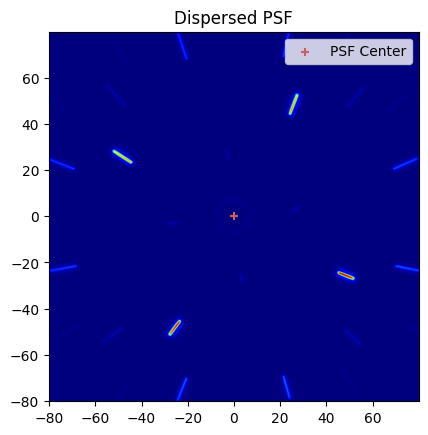

In [16]:
disp = 0.08
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)

true_center = np.array([0,0]) #we can worry about how well we can estimate this later


imshow_field(psf,cmap='jet')
plt.scatter(true_center[0],true_center[1],marker='+',color='indianred',label='PSF Center')
plt.legend()
plt.title('Dispersed PSF')

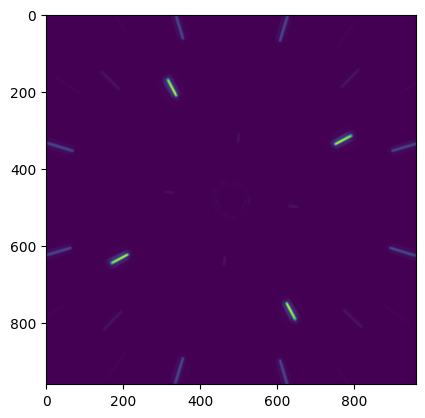

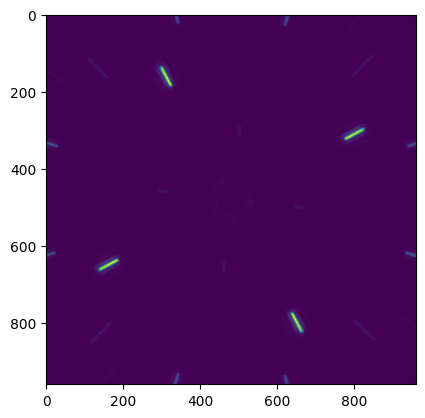

In [17]:
disp = 0.0
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
psf_stretched = radial_stretch_from_point(psf,1.1,center=center)
plt.figure()
plt.imshow(psf)
plt.figure()
plt.imshow(psf_stretched)

In [18]:
mse = np.sum((psf - psf_stretched)**2)
print(mse)

1292.8865241363178


In [19]:
y, x = np.meshgrid(
    np.arange(460, 500),
    np.arange(460, 500),
    indexing="ij"
)

indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

In [20]:
#go through the raster and see where the mse is minimized
disp = 0.0
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

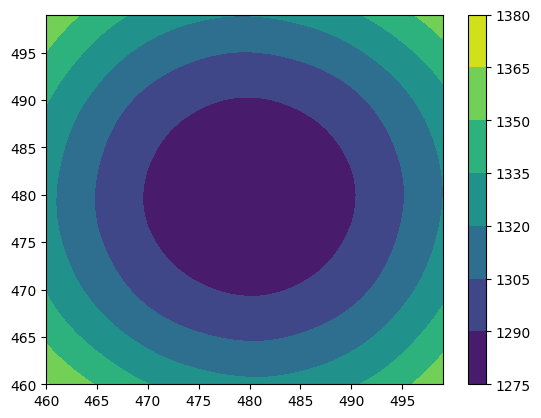

In [21]:
Z = np.array(Z)
plt.contourf(x,y,Z.reshape(y.shape))
plt.colorbar()

In [22]:
#same thing but with a dispersed PSF
disp = 0.01
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

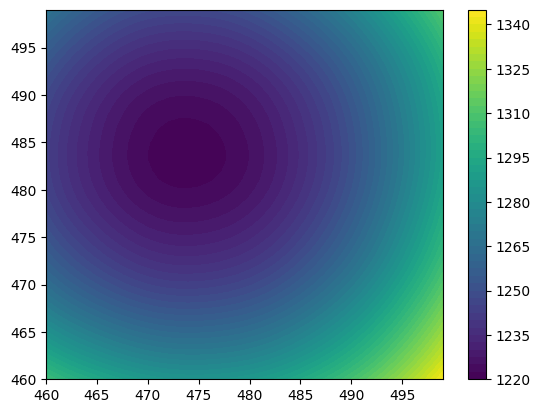

In [23]:
Z = np.array(Z)
plt.contourf(x,y,Z.reshape(y.shape),levels=50)
plt.colorbar()

looks like it's pretty easy to reproduce the result from pathak in simulation. what about on a lab image?

In [24]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
for img in step:
    img -= np.median(img)

img = step[26]
img = ADC.crop_image(img,extent=512,mask_diam=80)
psf = np.array(img.shaped)


center = psf.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

(np.int64(36), np.int64(49))
est radiation center at pixel index [[206. 255.]
 [206. 242.]]


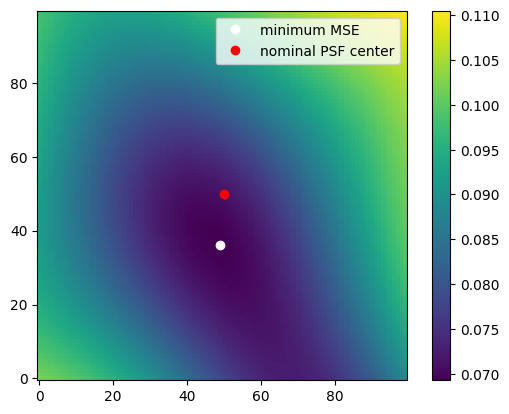

In [25]:
Z = np.array(Z)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)

rad_center = np.array([indices[a[1]],indices[a[0]]])
print(f'est radiation center at pixel index {rad_center}')

Z = np.reshape(Z,y.shape)
plt.imshow(Z,origin='lower')
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.plot(search_size/2,search_size/2,'o',color='red',label='nominal PSF center')
plt.legend()
plt.colorbar()

In [26]:
#and on an onsky image?
img = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/onsky_obs/2025-11-30_042051_tau_ceti_adc_tests_offset/camsci1/camsci1_20251130042618257616007.fits')
img = img.astype('float32')

#convert to hcipy field for cropping and masking
dim = np.sqrt(img.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(img.ravel(),pgrid)
img -= np.median(img)

In [27]:
img = ADC.crop_image(img,extent=512,mask_diam=80)
psf = np.array(img.shaped)

center = psf.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

(np.int64(55), np.int64(46))
est radiation center at pixel index [[206. 252.]
 [206. 261.]]


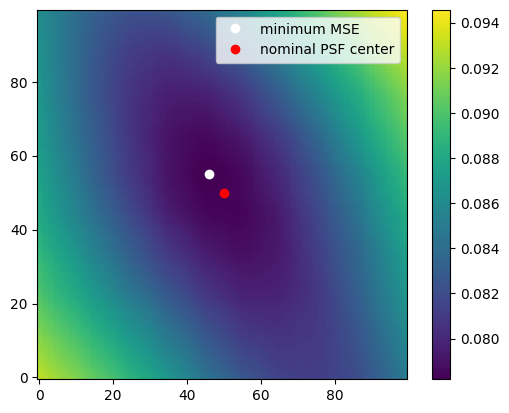

In [28]:
Z = np.array(Z)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)

rad_center = np.array([indices[a[1]],indices[a[0]]])
print(f'est radiation center at pixel index {rad_center}')

Z = np.reshape(Z,y.shape)
plt.imshow(Z,origin='lower')
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.plot(search_size/2,search_size/2,'o',color='red',label='nominal PSF center')
plt.legend()
plt.colorbar()

still seems to have worked. Let's try it on an entire calibration cube and see if it has a clear linear response.

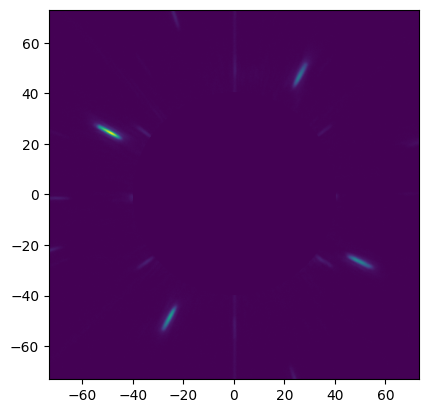

In [29]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
for img in step:
    img -= np.median(img)

img = step[26]
img = ADC.crop_image(img,extent=512,mask_diam=80)
imshow_field(img)
psf = np.array(img.shaped)

In [30]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
for img in step:
    img -= np.median(img)

(262144,)


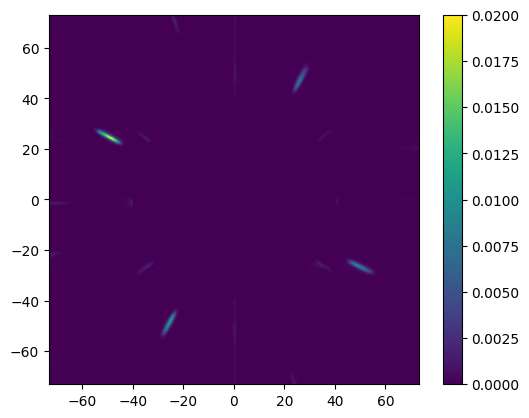

In [31]:
img = step[26]
img = ADC.crop_image(img,extent=512,mask_diam=80)
print(img.shape)
hp = ADC.hpf(img,20)
hp[hp <0] = 0
imshow_field(hp)
plt.colorbar()

In [32]:
center = img.shaped.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z_cube = []
rel_rad_centers = []
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 
speckle_list = [] #speckle angle list at each step

for i, field in enumerate(step):
    img = ADC.crop_image(field,mask_diam=80,extent=512)
    img = ADC.hpf(img,30)
    img[img <0] = 0
    a = ADC.all_speckle_angles(img,speckle_filter=True)
    speckle_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])

    Z = []
    psf = np.array(img.shaped)
    for index in indices:
        psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
        mse = np.sum((psf - psf_stretched)**2)
        Z.append(mse)

    Z = np.array(Z)
    a = np.unravel_index(Z.argmin(),y.shape)
    rel_rad_centers.append(a)

    Z_cube.append(np.reshape(Z,y.shape))

diffs13_list = np.array(diffs13_list)
diffs24_list = np.array(diffs24_list)
rel_rad_centerers = np.array(rel_rad_centers)

[ 0 97]


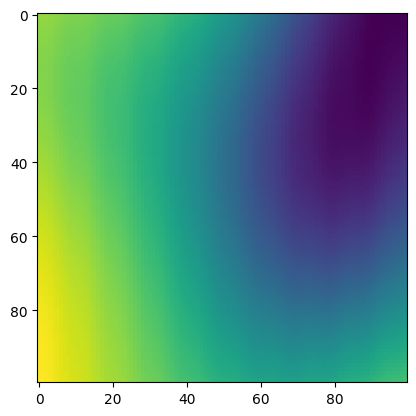

In [33]:
n = 50
plt.imshow(Z_cube[n])
print(rel_rad_centerers[n])

Slope of Speckles 1&3 Response: 1.2497892782046374
Offset of Speckles 1&3 Response: -1.0327866629284097
Slope of Speckles 2&4 Response: -3.4015240028054117
Offset of Speckles 2&4 Response: 3.0333850409431995


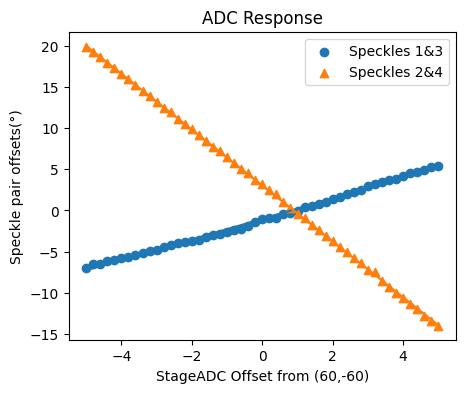

In [34]:
#plot the linear response
angle_offsets = np.linspace(-5,5,51) 

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(diffs13_list)
idxs24 = np.isfinite(diffs24_list)

h = [diffs13_list, diffs24_list]

avgs = [diffs13_list[idxs13], diffs24_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    plt.scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    plt.plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

#plt.scatter(0,0,color='Red')

plt.title('ADC Response')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Speckle pair offsets(°)')
plt.legend()
plt.show()

Text(0.5, 0, 'ADC shear angle (°)')

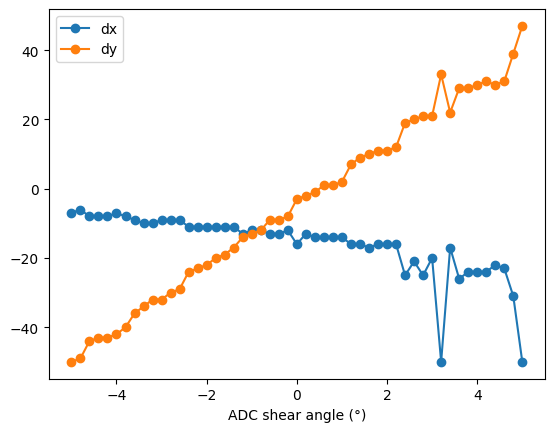

In [35]:
rel_rad_centerers = rel_rad_centerers - 50
plt.plot(angle_offsets,rel_rad_centerers[:,0],'o-',label='dx')
plt.plot(angle_offsets,rel_rad_centerers[:,1],'o-',label='dy')
plt.legend()
plt.xlabel('ADC shear angle (°)')

if i upsample everything can i get sub-pixel accuracy? that would help the curve to look more linear - it looks like its the pixel sampling, not the precision of the method that's limiting me here

In [36]:
#same thing but on the unsaturated dataset - what happens when our signal is lower?
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_unsat.fits')
for img in step:
    img -= np.median(img)

(250000,)


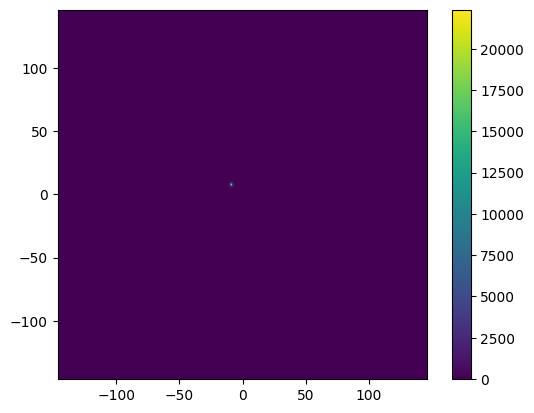

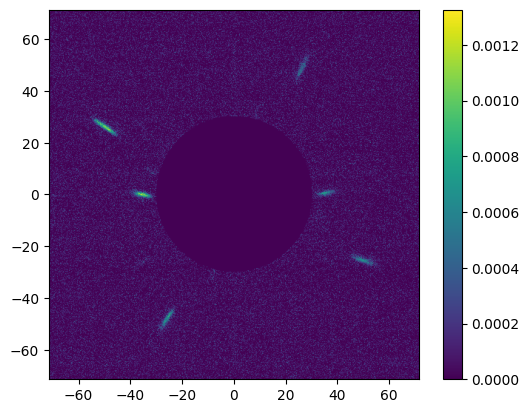

In [37]:
img = step[10]
imshow_field(img)
plt.colorbar()
plt.figure()
img = ADC.crop_image(img,extent=500,mask_diam=60)
print(img.shape)
# hp = ADC.hpf(img,20)
# hp[hp <0] = 0
imshow_field(img)
plt.colorbar()

In [46]:
center = img.shaped.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z_cube = []
rel_rad_centers = []

for i, field in enumerate(step):
    img = ADC.crop_image(field,mask_diam=80,extent=500)
    hp = ADC.hpf(img,20)
    hp = hp - ADC.hpf(hp,0.8)
    # a = ADC.all_speckle_angles(img,speckle_filter=True)
    # speckle_list.append(a)
    # diffs13_list.append(a[0] - a[2])
    # diffs24_list.append(a[1] - a[3])

    Z = []
    psf = np.array(img.shaped)
    for index in indices:
        psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
        mse = np.sum((psf - psf_stretched)**2)
        Z.append(mse)

    Z = np.array(Z)
    a = np.unravel_index(Z.argmin(),y.shape)
    rel_rad_centers.append(a)

    Z_cube.append(np.reshape(Z,y.shape))

rel_rad_centerers = np.array(rel_rad_centers)

[45 50]


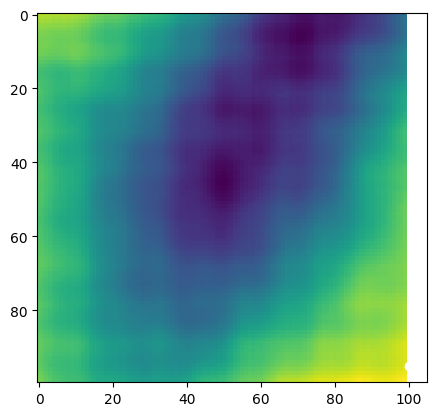

In [47]:
n = 26
plt.imshow(Z_cube[n])
print(rel_rad_centerers[n])

f = rel_rad_centerers[n] + 50

plt.plot(f[1],f[0],'o',color='white',label='minimum MSE')

Text(0.5, 0, 'ADC shear angle (°)')

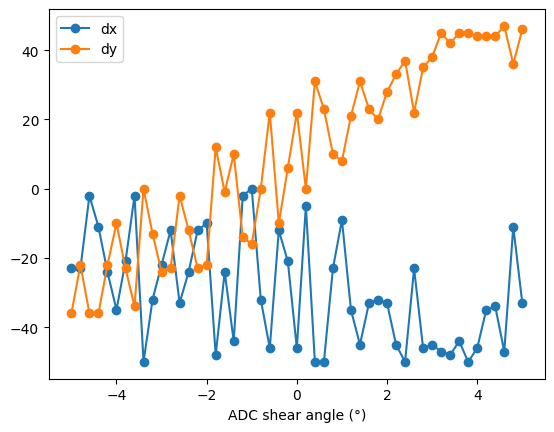

In [48]:
rel_rad_centerers = rel_rad_centerers - 50
angle_offsets = np.linspace(-5,5,51) 

plt.plot(angle_offsets,rel_rad_centerers[:,0],'o-',label='dx')
plt.plot(angle_offsets,rel_rad_centerers[:,1],'o-',label='dy')
plt.legend()
plt.xlabel('ADC shear angle (°)')